# Hospital Readmission Risk Prediction Using MLP
### Deep Learning | Healthcare Industry | CBIM Methodology

**Goal:** Predict whether a patient will be readmitted within 30 days of discharge using the Diabetes 130-US Hospitals dataset.

**Target definition**
- `1` = readmitted within 30 days (`<30`)
- `0` = not readmitted within 30 days (`>30` or `NO`)

**Model:** Multi-Layer Perceptron (MLP) built with TensorFlow/Keras Sequential API.

> **Important:** This is an educational prototype using historical data from 1999–2008. It is not a clinically validated decision-making system.

## Notebook roadmap

1. CBIM: business understanding
2. Environment setup and dataset loading
3. Data understanding and exploratory analysis
4. Data cleaning and leakage prevention
5. Feature preparation and patient-level data splitting
6. Encoding and scaling
7. MLP model design
8. Training experiments
9. Evaluation and error analysis
10. Patient-level predictions and business recommendations

Each task is separated into small cells so that the workflow is easy to follow and explain.

# Part 1 — CBIM: Business Understanding

### 1.1 Business problem

| **CBIM Element** | **Description** |
|---|---|
| Business problem | Hospitals need to identify diabetic patients who may be readmitted within 30 days after discharge. |
| Business need | Early identification can help care teams plan follow-up appointments, medication reviews and additional discharge support. |
| Dataset | Diabetes 130-US Hospitals for Years 1999–2008 (`diabetic_data.csv`). |
| Industry | Healthcare and medical analytics. |
| Proposed solution | Develop a supervised deep learning model using a Multi-Layer Perceptron (MLP) with TensorFlow/Keras. |
| Expected outcome | Estimate the likelihood of 30-day readmission to support better post-discharge care planning. |

### 1.2 Deep learning problem

| **CBIM Element** | **Description** |
|---|---|
| Problem type | Supervised learning. |
| Task | Binary classification. |
| Input data | Patient demographics, admission details, diagnoses, medications, laboratory information and hospital encounter characteristics available in the dataset. |
| Target column | `readmitted`. |
| Positive class | `<30` — readmitted within 30 days. |
| Negative class | `>30` or `NO` — not readmitted within 30 days. |
| Model | Multi-Layer Perceptron (MLP). |
| Framework | TensorFlow / Keras. |
| Model output | Predicted probability that a patient will be readmitted within 30 days. |

### 1.3 Business objectives

| **S.No.** | **Business objective** | **Expected result** |
|---:|---|---|
| 1 | Identify patients at higher risk of 30-day readmission. | Flag encounters with a higher predicted readmission risk. |
| 2 | Understand encounter characteristics associated with readmission. | Examine patterns and relationships in the available patient data. |
| 3 | Prepare the dataset for modelling. | Clean, transform and encode the data for MLP training. |
| 4 | Build an MLP using TensorFlow/Keras. | Train a supervised binary classification model. |
| 5 | Evaluate model performance using suitable classification metrics. | Report accuracy, precision, recall, F1-score and ROC-AUC where appropriate. |
| 6 | Study false positives and false negatives. | Understand the types of prediction errors using a confusion matrix. |
| 7 | Suggest practical post-discharge support strategies. | Recommend follow-up appointments, medication reviews and additional discharge support for clinical review. |



## Part 2 — Environment Setup

In [1]:
# Install the main libraries if they are not already available.
# In Google Colab, run this cell once when starting a new runtime.

%pip install -q tensorflow pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
# Import libraries used throughout the notebook.

import os
import zipfile
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, ConfusionMatrixDisplay,
    precision_recall_curve, RocCurveDisplay
)
from sklearn.utils.class_weight import compute_class_weight

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)

print("Pandas version:", pd.__version__)
print("TensorFlow version:", tf.__version__)

Pandas version: 3.1.0
TensorFlow version: 2.21.0


In [3]:
# Fix random seeds so that the experiment is more reproducible.

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("Random seed set to:", SEED)

Random seed set to: 42


## Part 3 — Locate and Load the Dataset

The dataset file used in this notebook is `diabetic_data.csv` from the Diabetes 130-US Hospitals dataset.

The CSV path below is set to the exact Windows file location provided. If you run this notebook on another computer or in Google Colab, update `CSV_PATH` to the location where the CSV file is stored.


In [4]:
# Load the dataset from the exact file path provided.

CSV_PATH = r"C:\Users\hp\Desktop\Trivikram\phase 2\Module 6 Deep Learning\diabetes+130-us+hospitals+for+years+1999-2008\diabetic_data.csv"

raw = pd.read_csv(CSV_PATH, low_memory=False)

# Keep df as an alias as well, so either variable name can be used.
df = raw

print("Dataset loaded successfully!")
print("Dataset shape:", raw.shape)

Dataset loaded successfully!
Dataset shape: (101766, 50)


In [5]:
# Display the first five records to understand the structure.

raw.head()

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,payer_code,medical_specialty,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,diag_1,diag_2,diag_3,number_diagnoses,max_glu_serum,A1Cresult,metformin,repaglinide,nateglinide,chlorpropamide,glimepiride,acetohexamide,glipizide,glyburide,tolbutamide,pioglitazone,rosiglitazone,acarbose,miglitol,troglitazone,tolazamide,examide,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),?,6,25,1,1,?,Pediatrics-Endocrinology,41,0,1,0,0,0,250.83,?,?,1,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),?,1,1,7,3,?,?,59,0,18,0,0,0,276,250.01,255,9,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),?,1,1,7,2,?,?,11,5,13,2,0,1,648,250,V27,6,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),?,1,1,7,2,?,?,44,1,16,0,0,0,8,250.43,403,7,NaN,NaN,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),?,1,1,7,1,?,?,51,0,8,0,0,0,197,157,250,5,NaN,NaN,No,No,No,No,No,No,Steady,No,No,No,No,No,No,No,No,No,No,Steady,No,No,No,No,No,Ch,Yes,NO


# Part 4 — Data Understanding and Exploratory Data Analysis

This stage checks the dataset structure, column types, summary statistics, missing values and duplicate records before any model is built.

In [6]:
# Check the size and data types of all columns.

print("Dataset shape:", raw.shape)
raw.info()

Dataset shape: (101766, 50)
<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num

In [7]:
# View summary statistics for numerical columns.

raw.describe().T

,count,mean,std,min,25%,50%,75%,max
encounter_id,101766.0,1.652016e+08,1.026403e+08,12522.0,84961194.0,152388987.0,2.302709e+08,443867222.0
patient_nbr,101766.0,5.433040e+07,3.869636e+07,135.0,23413221.0,45505143.0,8.754595e+07,189502619.0
admission_type_id,101766.0,2.024006e+00,1.445403e+00,1.0,1.0,1.0,3.000000e+00,8.0
discharge_disposition_id,101766.0,3.715642e+00,5.280166e+00,1.0,1.0,1.0,4.000000e+00,28.0
admission_source_id,101766.0,5.754437e+00,4.064081e+00,1.0,1.0,7.0,7.000000e+00,25.0
time_in_hospital,101766.0,4.395987e+00,2.985108e+00,1.0,2.0,4.0,6.000000e+00,14.0
num_lab_procedures,101766.0,4.309564e+01,1.967436e+01,1.0,31.0,44.0,5.700000e+01,132.0
num_procedures,101766.0,1.339730e+00,1.705807e+00,0.0,0.0,1.0,2.000000e+00,6.0
num_medications,101766.0,1.602184e+01,8.127566e+00,1.0,10.0,15.0,2.000000e+01,81.0
number_outpatient,101766.0,3.693572e-01,1.267265e+00,0.0,0.0,0.0,0.000000e+00,42.0


In [8]:
# View summary information for categorical columns.

raw.describe(include="object").T

,count,unique,top,freq
race,101766,6,Caucasian,76099
gender,101766,3,Female,54708
age,101766,10,[70-80),26068
weight,101766,10,?,98569
payer_code,101766,18,?,40256
medical_specialty,101766,73,?,49949
diag_1,101766,717,428,6862
diag_2,101766,749,276,6752
diag_3,101766,790,250,11555
max_glu_serum,5346,3,Norm,2597


In [9]:
# Count the missing values in every column.

missing_summary = pd.DataFrame({
    "Missing Count": raw.isna().sum(),
    "Missing Percentage": (raw.isna().mean() * 100).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage", ascending=False
)

missing_summary.head(20)

,Missing Count,Missing Percentage
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
race,0,0.00
gender,0,0.00
age,0,0.00
weight,0,0.00
admission_type_id,0,0.00
discharge_disposition_id,0,0.00
admission_source_id,0,0.00
time_in_hospital,0,0.00


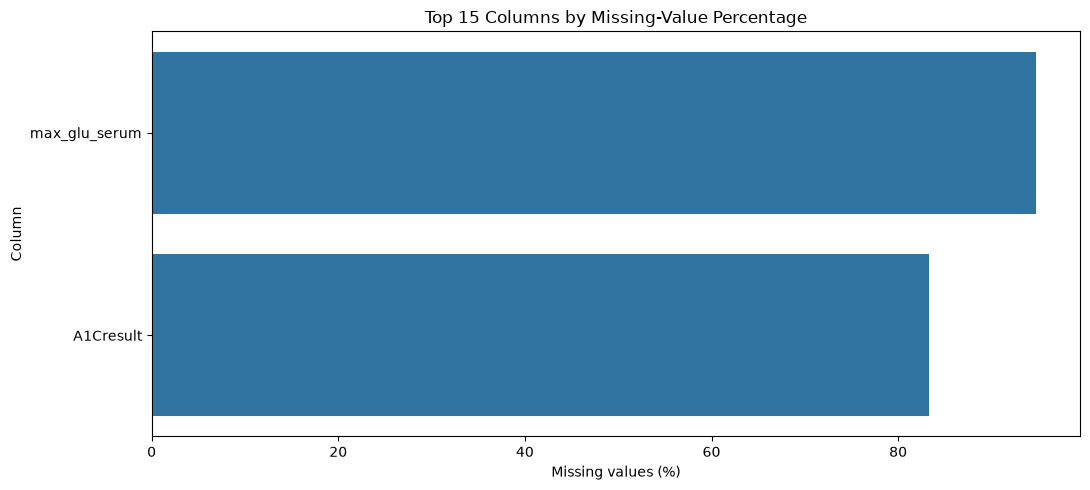

In [10]:
# Visualize the columns with the highest missing-value percentages.

top_missing = missing_summary[missing_summary["Missing Count"] > 0].head(15)

plt.figure(figsize=(11, 5))
sns.barplot(
    x=top_missing["Missing Percentage"],
    y=top_missing.index
)
plt.title("Top 15 Columns by Missing-Value Percentage")
plt.xlabel("Missing values (%)")
plt.ylabel("Column")
plt.tight_layout()
plt.show()

In [11]:
# Check complete duplicate rows and repeated patient identifiers.

print("Exact duplicate rows:", raw.duplicated().sum())

if "patient_nbr" in raw.columns:
    print("Unique patients:", raw["patient_nbr"].nunique())
    print("Repeated patient records:", raw["patient_nbr"].duplicated().sum())

Exact duplicate rows: 0
Unique patients: 71518
Repeated patient records: 30248


In [12]:
# Check the original readmission categories.

raw["readmitted"].value_counts(dropna=False)

readmitted
NO     54864
>30    35545
<30    11357
Name: count, dtype: int64

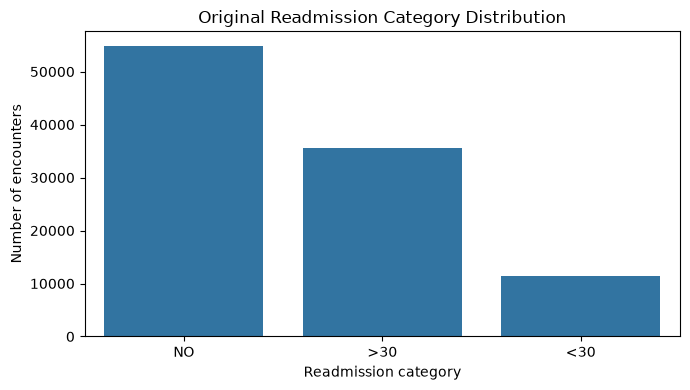

In [13]:
# Plot the distribution of the original readmission categories.

plt.figure(figsize=(7, 4))
sns.countplot(data=raw, x="readmitted", order=["NO", ">30", "<30"])
plt.title("Original Readmission Category Distribution")
plt.xlabel("Readmission category")
plt.ylabel("Number of encounters")
plt.tight_layout()
plt.show()

### 4.1 Initial observations

The dataset contains multiple encounters for some patients. Therefore, a normal random row split could place records from the same patient in both training and testing data. Later, we use a patient-grouped split to reduce this risk.

In this dataset, `?` is also used to represent unavailable categorical values. We will convert it into a missing value during cleaning.

# Part 5 — Target Creation and Data Cleaning

### 5.1 Convert the target into a binary label

The assignment defines:
- `<30` as class `1`.
- `>30` and `NO` as class `0`.

This notebook follows that definition exactly.

In [14]:
# Create the binary target column.

df = raw.copy()
df["target"] = (df["readmitted"] == "<30").astype("int8")

print(df["target"].value_counts())

target
0    90409
1    11357
Name: count, dtype: int64


In [15]:
# Display the percentage of each target class.

target_percentages = (
    df["target"].value_counts(normalize=True).sort_index() * 100
).round(2)

print("Class 0 = No readmission within 30 days")
print("Class 1 = Readmission within 30 days")
display(target_percentages)

Class 0 = No readmission within 30 days
Class 1 = Readmission within 30 days


target
0    88.84
1    11.16
Name: proportion, dtype: float64

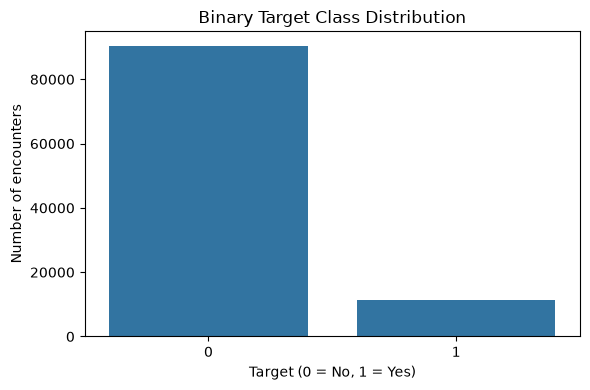

In [16]:
# Plot the binary target distribution to inspect class imbalance.

plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="target")
plt.title("Binary Target Class Distribution")
plt.xlabel("Target (0 = No, 1 = Yes)")
plt.ylabel("Number of encounters")
plt.tight_layout()
plt.show()

### 5.2 Handle special missing-value markers

The dataset uses `?` in some categorical columns. These values are not useful categories, so convert them to `NaN` and handle them during preprocessing.

In [17]:
# Replace question marks with proper missing values.

df = df.replace("?", np.nan)

print("Question-mark markers remaining:", (df == "?").sum().sum())

Question-mark markers remaining: 0


In [18]:
# Review missing values again after converting question marks.

clean_missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (df.isna().mean() * 100).round(2)
})

clean_missing = clean_missing[clean_missing["Missing Count"] > 0]
clean_missing.sort_values("Missing Percentage", ascending=False).head(20)

,Missing Count,Missing Percentage
weight,98569,96.86
max_glu_serum,96420,94.75
A1Cresult,84748,83.28
medical_specialty,49949,49.08
payer_code,40256,39.56
race,2273,2.23
diag_3,1423,1.40
diag_2,358,0.35
diag_1,21,0.02


### 5.3 Missing-value treatment plan

- `weight`: remove because most values are unavailable; imputing almost the entire column would add very little reliable information.
- `payer_code` and `medical_specialty`: retain and let the categorical imputer use the most frequent category or an explicit unknown value.
- Other categorical missing values: replace with `Unknown`.
- Numerical missing values: fill using the median, fitted on training data only.

The preprocessing pipeline below performs the imputation using training data, which helps prevent information from the validation and test sets leaking into training.

In [19]:
# Remove weight because it has very high missingness.

if "weight" in df.columns:
    df = df.drop(columns=["weight"])

print("Shape after dropping weight:", df.shape)

Shape after dropping weight: (101766, 50)


In [20]:
# Remove exact duplicate rows, if any are present.

duplicate_count = df.duplicated().sum()
df = df.drop_duplicates().copy()

print("Duplicate rows removed:", duplicate_count)
print("New dataset shape:", df.shape)

Duplicate rows removed: 0
New dataset shape: (101766, 50)


### 5.4 Reduce impossible readmission outcomes

Some discharge dispositions indicate that the patient expired or was transferred to hospice. Such encounters cannot represent a normal future readmission opportunity. We exclude the commonly used disposition codes `11, 13, 14, 19, 20, 21` for this educational prediction task.

This is a documented modelling choice; the number of removed records is printed below.

In [21]:
# Exclude expired or hospice-related discharge dispositions.

excluded_discharge_codes = [11, 13, 14, 19, 20, 21]

before_filter = len(df)

if "discharge_disposition_id" in df.columns:
    df["discharge_disposition_id"] = pd.to_numeric(
        df["discharge_disposition_id"], errors="coerce"
    )
    df = df[~df["discharge_disposition_id"].isin(excluded_discharge_codes)].copy()

print("Rows before filter:", before_filter)
print("Rows after filter:", len(df))
print("Rows excluded:", before_filter - len(df))

Rows before filter: 101766
Rows after filter: 99343
Rows excluded: 2423


### 5.5 Select prediction features and consider leakage

We do not use `readmitted` as an input because it is the answer we want the model to predict. We also remove `encounter_id` and `patient_nbr`, because they are identifiers rather than generalizable clinical features.

The selected features describe patient demographics, admission circumstances, prior utilization, treatment and encounter characteristics. They should be reviewed against the intended prediction time (discharge) before any real-world use.

In [22]:
# Create the feature list using columns that exist in the dataset.

candidate_features = [
    "race", "gender", "age",
    "admission_type_id", "discharge_disposition_id", "admission_source_id",
    "time_in_hospital", "payer_code", "medical_specialty",
    "num_lab_procedures", "num_procedures", "num_medications",
    "number_outpatient", "number_emergency", "number_inpatient",
    "number_diagnoses", "max_glu_serum", "A1Cresult",
    "metformin", "repaglinide", "nateglinide", "chlorpropamide",
    "glimepiride", "acetohexamide", "glipizide", "glyburide",
    "tolbutamide", "pioglitazone", "rosiglitazone", "acarbose",
    "miglitol", "troglitazone", "tolazamide", "insulin",
    "glyburide-metformin", "glipizide-metformin",
    "glimepiride-pioglitazone", "metformin-rosiglitazone",
    "metformin-pioglitazone", "change", "diabetesMed"
]

feature_cols = [col for col in candidate_features if col in df.columns]

print("Number of selected features:", len(feature_cols))
print(feature_cols)

Number of selected features: 41
['race', 'gender', 'age', 'admission_type_id', 'discharge_disposition_id', 'admission_source_id', 'time_in_hospital', 'payer_code', 'medical_specialty', 'num_lab_procedures', 'num_procedures', 'num_medications', 'number_outpatient', 'number_emergency', 'number_inpatient', 'number_diagnoses', 'max_glu_serum', 'A1Cresult', 'metformin', 'repaglinide', 'nateglinide', 'chlorpropamide', 'glimepiride', 'acetohexamide', 'glipizide', 'glyburide', 'tolbutamide', 'pioglitazone', 'rosiglitazone', 'acarbose', 'miglitol', 'troglitazone', 'tolazamide', 'insulin', 'glyburide-metformin', 'glipizide-metformin', 'glimepiride-pioglitazone', 'metformin-rosiglitazone', 'metformin-pioglitazone', 'change', 'diabetesMed']


In [23]:
# Keep the selected features, target and patient group identifier.

model_data = df[feature_cols + ["target", "patient_nbr"]].copy()

X = model_data[feature_cols].copy()
y = model_data["target"].astype("int8").copy()
groups = model_data["patient_nbr"].copy()

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (99343, 41)
Target shape: (99343,)


# Part 6 — Train, Validation and Test Split

We use `StratifiedGroupKFold` so that:
- Encounters from one patient stay within one split.
- The target class distribution is kept as similar as possible.
- The test set remains separate until final evaluation.

The approximate split is 64% training, 16% validation and 20% testing.

In [24]:
# First split: reserve one fold (approximately 20%) for final testing.

splitter_test = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=SEED
)

train_validation_indices, test_indices = next(
    splitter_test.split(X, y, groups)
)

X_train_validation = X.iloc[train_validation_indices].copy()
y_train_validation = y.iloc[train_validation_indices].copy()
groups_train_validation = groups.iloc[train_validation_indices].copy()

X_test = X.iloc[test_indices].copy()
y_test = y.iloc[test_indices].copy()
groups_test = groups.iloc[test_indices].copy()

print("Train + validation rows:", len(X_train_validation))
print("Test rows:", len(X_test))

Train + validation rows: 79473
Test rows: 19870


In [25]:
# Second split: divide the remaining data into training and validation folds.

splitter_validation = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=SEED + 1
)

train_indices, validation_indices = next(
    splitter_validation.split(
        X_train_validation,
        y_train_validation,
        groups_train_validation
    )
)

X_train = X_train_validation.iloc[train_indices].copy()
y_train = y_train_validation.iloc[train_indices].copy()

X_validation = X_train_validation.iloc[validation_indices].copy()
y_validation = y_train_validation.iloc[validation_indices].copy()

print("Training rows:", len(X_train))
print("Validation rows:", len(X_validation))
print("Testing rows:", len(X_test))

Training rows: 63578
Validation rows: 15895
Testing rows: 19870


In [26]:
# Compare the positive-class percentage across all three splits.

split_summary = pd.DataFrame({
    "Rows": [len(y_train), len(y_validation), len(y_test)],
    "Readmitted within 30 days (%)": [
        y_train.mean() * 100,
        y_validation.mean() * 100,
        y_test.mean() * 100
    ]
}, index=["Training", "Validation", "Testing"])

split_summary.round(2)

,Rows,Readmitted within 30 days (%)
Training,63578,11.39
Validation,15895,11.39
Testing,19870,11.39


In [27]:
# Verify that no patient identifier appears in more than one split.

train_patients = set(groups.iloc[train_validation_indices].iloc[train_indices])
validation_patients = set(groups.iloc[train_validation_indices].iloc[validation_indices])
test_patients = set(groups_test)

print("Train and validation overlap:", len(train_patients & validation_patients))
print("Train and test overlap:", len(train_patients & test_patients))
print("Validation and test overlap:", len(validation_patients & test_patients))

Train and validation overlap: 0
Train and test overlap: 0
Validation and test overlap: 0


# Part 7 — Encoding and Scaling

Neural networks work better when numerical features are on comparable scales. Categorical variables must also be converted into numeric form.

We use a `ColumnTransformer`:
- Numerical columns: median imputation followed by standard scaling.
- Categorical columns: fill missing values with `Unknown`, then one-hot encode.
- The transformer is fitted only on the training data.

In [28]:
# Identify numerical and categorical feature columns.

numeric_features = X_train.select_dtypes(include=["number"]).columns.tolist()
categorical_features = [
    col for col in X_train.columns if col not in numeric_features
]

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))

Numerical features: 11
Categorical features: 30


In [29]:
# Import imputers and build the preprocessing pipelines.

from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Unknown")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", min_frequency=0.01))
])

print("Preprocessing pipelines created.")

Preprocessing pipelines created.


In [30]:
# Combine numerical and categorical transformations.

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features)
    ],
    remainder="drop"
)

print("ColumnTransformer is ready.")

ColumnTransformer is ready.


In [31]:
# Fit preprocessing on training data and transform the other splits.

X_train_processed = preprocessor.fit_transform(X_train)
X_validation_processed = preprocessor.transform(X_validation)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_validation_processed.shape)
print("Processed test shape:", X_test_processed.shape)

Processed training shape: (63578, 114)
Processed validation shape: (15895, 114)
Processed test shape: (19870, 114)


In [32]:
# Convert sparse matrices to dense arrays when needed, then use float32 for TensorFlow.

def to_float32_array(data):
    if hasattr(data, "toarray"):
        data = data.toarray()
    return np.asarray(data, dtype=np.float32)

X_train_processed = to_float32_array(X_train_processed)
X_validation_processed = to_float32_array(X_validation_processed)
X_test_processed = to_float32_array(X_test_processed)

y_train_array = y_train.to_numpy(dtype=np.float32)
y_validation_array = y_validation.to_numpy(dtype=np.float32)
y_test_array = y_test.to_numpy(dtype=np.float32)

print("Processed training shape:", X_train_processed.shape)
print("Processed validation shape:", X_validation_processed.shape)
print("Processed test shape:", X_test_processed.shape)
print("TensorFlow input data is ready.")

Processed training shape: (63578, 114)
Processed validation shape: (15895, 114)
Processed test shape: (19870, 114)
TensorFlow input data is ready.


# Part 8 — MLP Architecture Design

The network uses the Keras Sequential API:
- Input layer: receives the processed feature vector.
- Hidden layer 1: 64 neurons with ReLU.
- Dropout: helps reduce overfitting.
- Hidden layer 2: 32 neurons with ReLU.
- Output layer: one neuron with Sigmoid to produce a probability between 0 and 1.

We use Adam as the optimizer and Binary Crossentropy as the loss function, as required by the assignment.

In [33]:
# Define a function that creates the MLP model.

def create_mlp(input_dimension):
    model = keras.Sequential([
        keras.Input(shape=(input_dimension,)),
        layers.Dense(64, activation="relu"),
        layers.Dropout(0.30),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.20),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="binary_crossentropy",
        metrics=[
            keras.metrics.BinaryAccuracy(name="accuracy"),
            keras.metrics.AUC(name="auc")
        ]
    )

    return model

print("MLP builder function created.")

MLP builder function created.


In [34]:
# Build the first model and inspect its architecture.

input_dimension = X_train_processed.shape[1]
model = create_mlp(input_dimension)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         7,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,473 (37.00 KB)

 Trainable params: 9,473 (37.00 KB)

 Non-trainable params: 0 (0.00 B)

# Part 9 — Handle Class Imbalance and Train the Model

The `<30` group is usually smaller than the other readmission categories. If the model focuses only on the majority class, it may miss many patients who are readmitted within 30 days.

We calculate class weights from the training labels and use early stopping to reduce unnecessary training and monitor validation performance.

In [35]:
# Calculate balanced class weights from the training set only.

class_values = np.array([0, 1])
weights = compute_class_weight(
    class_weight="balanced",
    classes=class_values,
    y=y_train_array.astype(int)
)

class_weights = {
    0: float(weights[0]),
    1: float(weights[1])
}

print("Class weights:", class_weights)

Class weights: {0: 0.564255032127516, 1: 4.3907458563535915}


In [36]:
# Set callbacks for early stopping and learning-rate reduction.

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_auc",
    mode="max",
    patience=4,
    restore_best_weights=True
)

reduce_lr = keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=0.00001
)

print("Training callbacks are ready.")

Training callbacks are ready.


### 9.1 Training experiments — compare batch sizes

To satisfy the assignment's training-experiment requirement, we compare batch sizes 128 and 256. Both experiments use the same training and validation data and the same model structure. These short runs are used only to choose a practical batch size; the final model is trained separately.

In [37]:
# Experiment A: train an MLP with batch size 128.

experiment_model_128 = create_mlp(input_dimension)
history_128 = experiment_model_128.fit(
    X_train_processed,
    y_train_array,
    validation_data=(X_validation_processed, y_validation_array),
    epochs=8,
    batch_size=128,
    class_weight=class_weights,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=2, restore_best_weights=True)
    ],
    verbose=1
)
print('Experiment A completed.')

Epoch 1/8
497/497 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step - accuracy: 0.6111 - auc: 0.6103 - loss: 0.6733 - val_accuracy: 0.6233 - val_auc: 0.6388 - val_loss: 0.6666
Epoch 2/8
497/497 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6305 - auc: 0.6386 - loss: 0.6622 - val_accuracy: 0.6319 - val_auc: 0.6460 - val_loss: 0.6526
Epoch 3/8
497/497 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6244 - auc: 0.6465 - loss: 0.6592 - val_accuracy: 0.5818 - val_auc: 0.6458 - val_loss: 0.6701
Epoch 4/8
497/497 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6148 - auc: 0.6509 - loss: 0.6567 - val_accuracy: 0.5931 - val_auc: 0.6483 - val_loss: 0.6559
Epoch 5/8
497/497 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6184 - auc: 0.6547 - loss: 0.6558 - val_accuracy: 0.5957 - val_auc: 0.6505 - val_loss: 0.6522
Epoch 6/8
497/497 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6140 - auc: 0.6572 - loss: 0.6533 - val_accuracy: 0.6007 - val_auc: 0.6501 - val_loss: 0.6510
Epoch 7/8
497/497 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/

In [38]:
# Experiment B: train an MLP with batch size 256.

experiment_model_256 = create_mlp(input_dimension)
history_256 = experiment_model_256.fit(
    X_train_processed,
    y_train_array,
    validation_data=(X_validation_processed, y_validation_array),
    epochs=8,
    batch_size=256,
    class_weight=class_weights,
    callbacks=[
        keras.callbacks.EarlyStopping(monitor='val_auc', mode='max', patience=2, restore_best_weights=True)
    ],
    verbose=1
)
print('Experiment B completed.')

Epoch 1/8
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.6004 - auc: 0.6038 - loss: 0.6757 - val_accuracy: 0.6617 - val_auc: 0.6378 - val_loss: 0.6521
Epoch 2/8
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6220 - auc: 0.6341 - loss: 0.6636 - val_accuracy: 0.6476 - val_auc: 0.6454 - val_loss: 0.6530
Epoch 3/8
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6180 - auc: 0.6434 - loss: 0.6597 - val_accuracy: 0.6360 - val_auc: 0.6488 - val_loss: 0.6494
Epoch 4/8
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6164 - auc: 0.6489 - loss: 0.6573 - val_accuracy: 0.6182 - val_auc: 0.6514 - val_loss: 0.6555
Epoch 5/8
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6219 - auc: 0.6541 - loss: 0.6555 - val_accuracy: 0.6309 - val_auc: 0.6519 - val_loss: 0.6493
Epoch 6/8
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6252 - auc: 0.6570 - loss: 0.6544 - val_accuracy: 0.6644 - val_auc: 0.6519 - val_loss: 0.6314
Epoch 7/8
249/249 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/

In [39]:
# Compare the best validation AUC reached by each batch-size experiment.

experiment_comparison = pd.DataFrame({
    'Batch Size': [128, 256],
    'Best Validation AUC': [max(history_128.history['val_auc']), max(history_256.history['val_auc'])],
    'Epochs Completed': [len(history_128.history['loss']), len(history_256.history['loss'])]
})

display(experiment_comparison.round(4))

,Batch Size,Best Validation AUC,Epochs Completed
0,128,0.6523,8
1,256,0.6519,7


In [40]:
# Select the batch size with the higher validation AUC for final training.

selected_batch_size = int(
    experiment_comparison.loc[experiment_comparison['Best Validation AUC'].idxmax(), 'Batch Size']
)
print('Selected batch size:', selected_batch_size)

Selected batch size: 128


### 9.2 Train the final MLP

The final model is initialized from scratch and trained using the selected batch size. Early stopping monitors validation AUC and restores the best weights.

In [41]:
# Train the model with a batch size of 256.

history = model.fit(
    X_train_processed,
    y_train_array,
    validation_data=(X_validation_processed, y_validation_array),
    epochs=30,
    batch_size=selected_batch_size,
    class_weight=class_weights,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/30
497/497 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.6054 - auc: 0.6025 - loss: 0.6764 - val_accuracy: 0.6331 - val_auc: 0.6445 - val_loss: 0.6670 - learning_rate: 0.0010
Epoch 2/30
497/497 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6265 - auc: 0.6378 - loss: 0.6628 - val_accuracy: 0.5738 - val_auc: 0.6473 - val_loss: 0.6730 - learning_rate: 0.0010
Epoch 3/30
497/497 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6234 - auc: 0.6475 - loss: 0.6585 - val_accuracy: 0.5976 - val_auc: 0.6517 - val_loss: 0.6680 - learning_rate: 0.0010
Epoch 4/30
497/497 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6325 - auc: 0.6530 - loss: 0.6560 - val_accuracy: 0.6412 - val_auc: 0.6531 - val_loss: 0.6363 - learning_rate: 5.0000e-04
Epoch 5/30
497/497 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6342 - auc: 0.6589 - loss: 0.6532 - val_accuracy: 0.6355 - val_auc: 0.6535 - val_loss: 0.6397 - learning_rate: 5.0000e-04
Epoch 6/30
497/497 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.6295 -

In [42]:
# Display the number of epochs actually completed.

print("Epochs completed:", len(history.history["loss"]))

Epochs completed: 16


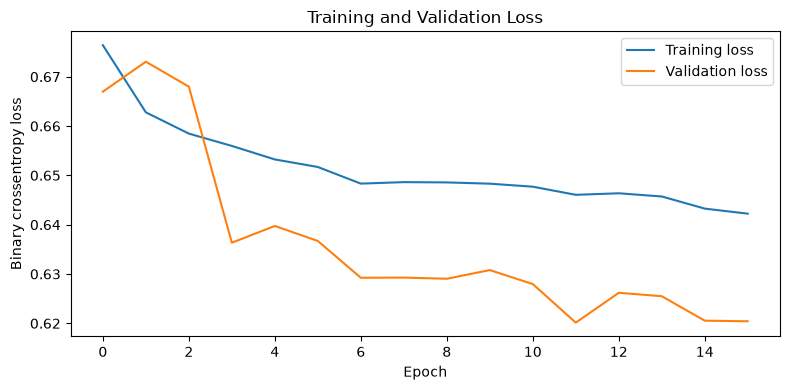

In [43]:
# Plot training and validation loss.

plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary crossentropy loss")
plt.legend()
plt.tight_layout()
plt.show()

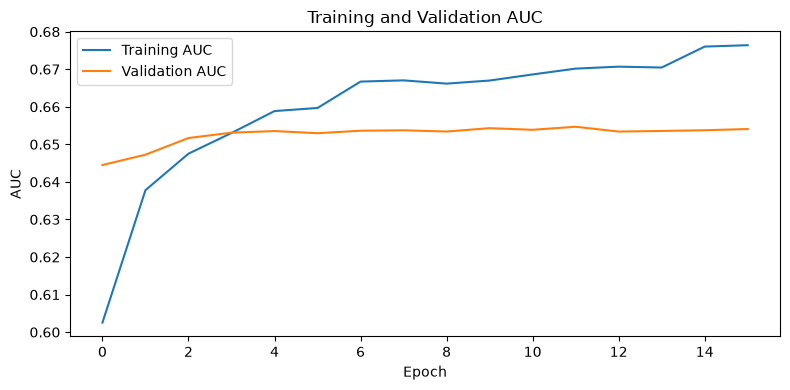

In [44]:
# Plot training and validation AUC.

plt.figure(figsize=(8, 4))
plt.plot(history.history["auc"], label="Training AUC")
plt.plot(history.history["val_auc"], label="Validation AUC")
plt.title("Training and Validation AUC")
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.legend()
plt.tight_layout()
plt.show()

### 9.1 Generalization check

Compare training and validation curves. A very high training score with a much lower validation score may indicate overfitting. Similar performance is a better sign that the model can generalize to unseen encounters.

In [45]:
# Print the final recorded training and validation metrics.

generalization_check = pd.DataFrame({
    "Metric": ["Loss", "Accuracy", "AUC"],
    "Training": [
        history.history["loss"][-1],
        history.history["accuracy"][-1],
        history.history["auc"][-1]
    ],
    "Validation": [
        history.history["val_loss"][-1],
        history.history["val_accuracy"][-1],
        history.history["val_auc"][-1]
    ]
})

generalization_check.round(4)

,Metric,Training,Validation
0,Loss,0.6422,0.6204
1,Accuracy,0.6275,0.6445
2,AUC,0.6764,0.6541


# Part 10 — Model Evaluation

The final test set is used only after training and model decisions are complete. We evaluate using accuracy, precision, recall, F1-score, ROC-AUC and PR-AUC.

Recall is particularly important in this use case because a false negative means the model failed to flag a patient who was readmitted within 30 days.

In [46]:
# Predict readmission probabilities for the untouched test set.

test_probabilities = model.predict(
    X_test_processed,
    batch_size=1024,
    verbose=0
).ravel()

print("Number of test predictions:", len(test_probabilities))
print("First five risk probabilities:", test_probabilities[:5])

Number of test predictions: 19870
First five risk probabilities: [0.13224679 0.441887   0.5429188  0.53258735 0.41407254]


In [47]:
# Calculate the main evaluation metrics at the default 0.50 threshold.

DEFAULT_THRESHOLD = 0.50
test_predictions_default = (test_probabilities >= DEFAULT_THRESHOLD).astype(int)

default_metrics = {
    "Accuracy": accuracy_score(y_test_array, test_predictions_default),
    "Precision": precision_score(y_test_array, test_predictions_default, zero_division=0),
    "Recall": recall_score(y_test_array, test_predictions_default, zero_division=0),
    "F1-score": f1_score(y_test_array, test_predictions_default, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_array, test_probabilities),
    "PR-AUC": average_precision_score(y_test_array, test_probabilities)
}

pd.DataFrame(default_metrics, index=["Test score"]).T.round(4)

,Test score
Accuracy,0.6380
Precision,0.1711
Recall,0.5665
F1-score,0.2628
ROC-AUC,0.6512
PR-AUC,0.2016


In [48]:
# Display a detailed classification report.

print(classification_report(
    y_test_array,
    test_predictions_default,
    target_names=["No readmission within 30 days", "Readmitted within 30 days"],
    zero_division=0
))

                               precision    recall  f1-score   support

No readmission within 30 days       0.92      0.65      0.76     17607
    Readmitted within 30 days       0.17      0.57      0.26      2263

                     accuracy                           0.64     19870
                    macro avg       0.55      0.61      0.51     19870
                 weighted avg       0.84      0.64      0.70     19870



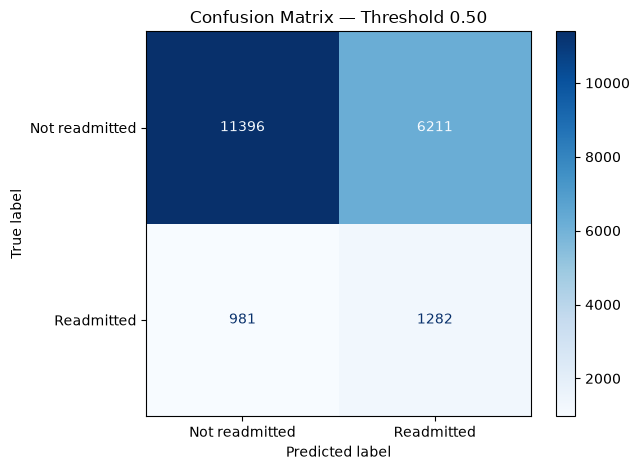

In [49]:
# Plot the confusion matrix.

cm_default = confusion_matrix(y_test_array, test_predictions_default)

ConfusionMatrixDisplay(
    confusion_matrix=cm_default,
    display_labels=["Not readmitted", "Readmitted"]
).plot(cmap="Blues", values_format="d")

plt.title("Confusion Matrix — Threshold 0.50")
plt.tight_layout()
plt.show()

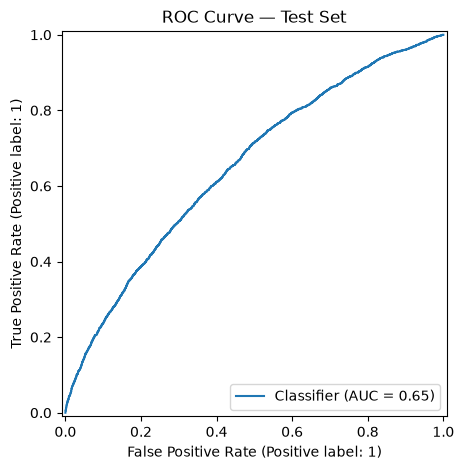

In [50]:
# Plot the ROC curve.

RocCurveDisplay.from_predictions(y_test_array, test_probabilities)
plt.title("ROC Curve — Test Set")
plt.tight_layout()
plt.show()

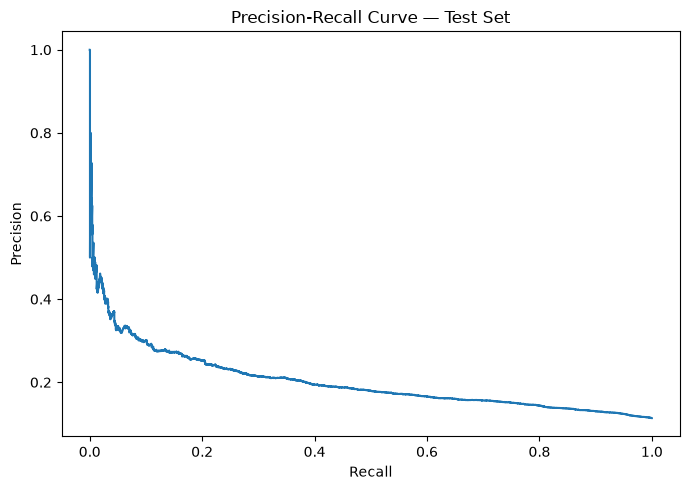

In [51]:
# Plot the precision-recall curve.

precision_values, recall_values, threshold_values = precision_recall_curve(
    y_test_array, test_probabilities
)

plt.figure(figsize=(7, 5))
plt.plot(recall_values, precision_values)
plt.title("Precision-Recall Curve — Test Set")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.tight_layout()
plt.show()

## 10.1 Select an operating threshold using validation data

A probability of 0.50 is only a default decision threshold. We select a threshold using the validation set, not the test set. The threshold below maximizes validation F1-score. The selected threshold is then applied once to the test predictions.

In [52]:
# Generate validation probabilities.

validation_probabilities = model.predict(
    X_validation_processed,
    batch_size=1024,
    verbose=0
).ravel()

print("Validation predictions generated.")

Validation predictions generated.


In [53]:
# Find the threshold with the best validation F1-score.

val_precision, val_recall, val_thresholds = precision_recall_curve(
    y_validation_array, validation_probabilities
)

val_f1_scores = (
    2 * val_precision[:-1] * val_recall[:-1]
    / (val_precision[:-1] + val_recall[:-1] + 1e-8)
)

best_threshold_index = int(np.argmax(val_f1_scores))
selected_threshold = float(val_thresholds[best_threshold_index])

print("Selected validation threshold:", round(selected_threshold, 4))
print("Best validation F1-score:", round(float(val_f1_scores[best_threshold_index]), 4))

Selected validation threshold: 0.536
Best validation F1-score: 0.2709


In [54]:
# Apply the validation-selected threshold to the test probabilities.

test_predictions = (test_probabilities >= selected_threshold).astype(int)

selected_metrics = {
    "Accuracy": accuracy_score(y_test_array, test_predictions),
    "Precision": precision_score(y_test_array, test_predictions, zero_division=0),
    "Recall": recall_score(y_test_array, test_predictions, zero_division=0),
    "F1-score": f1_score(y_test_array, test_predictions, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test_array, test_probabilities),
    "PR-AUC": average_precision_score(y_test_array, test_probabilities)
}

pd.DataFrame(selected_metrics, index=["Test score — selected threshold"]).T.round(4)

,Test score — selected threshold
Accuracy,0.7173
Precision,0.1876
Recall,0.4450
F1-score,0.2639
ROC-AUC,0.6512
PR-AUC,0.2016


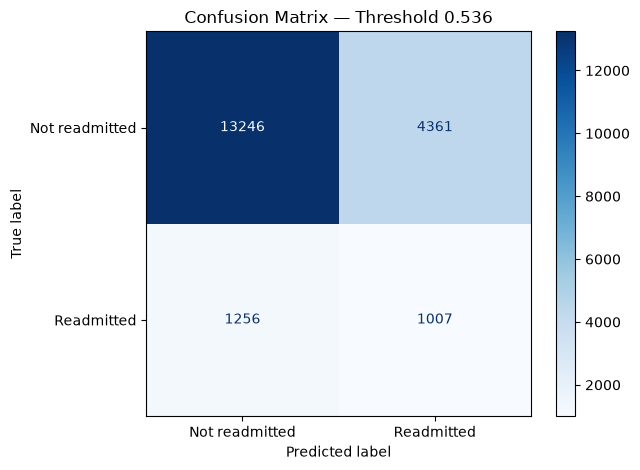

In [55]:
# Plot the confusion matrix using the selected threshold.

cm_selected = confusion_matrix(y_test_array, test_predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm_selected,
    display_labels=["Not readmitted", "Readmitted"]
).plot(cmap="Blues", values_format="d")

plt.title(f"Confusion Matrix — Threshold {selected_threshold:.3f}")
plt.tight_layout()
plt.show()

# Part 11 — Structured Error Analysis

- **False Negative (FN):** Actual readmission was 1, but the model predicted 0. These are missed high-risk patients.
- **False Positive (FP):** Actual readmission was 0, but the model predicted 1. These patients may receive an unnecessary additional follow-up.

Both types of error matter, but missing a genuinely high-risk patient may have a greater clinical and operational cost.

In [56]:
# Create a table containing actual labels, predictions and probabilities.

error_analysis = pd.DataFrame({
    "Actual": y_test_array.astype(int),
    "Predicted": test_predictions,
    "Risk Probability": test_probabilities
}, index=X_test.index)

error_analysis["Outcome"] = np.select(
    [
        (error_analysis["Actual"] == 1) & (error_analysis["Predicted"] == 1),
        (error_analysis["Actual"] == 0) & (error_analysis["Predicted"] == 1),
        (error_analysis["Actual"] == 1) & (error_analysis["Predicted"] == 0)
    ],
    ["True Positive", "False Positive", "False Negative"],
    default="True Negative"
)

error_analysis["Outcome"].value_counts()

Outcome
True Negative     13246
False Positive     4361
False Negative     1256
True Positive      1007
Name: count, dtype: int64

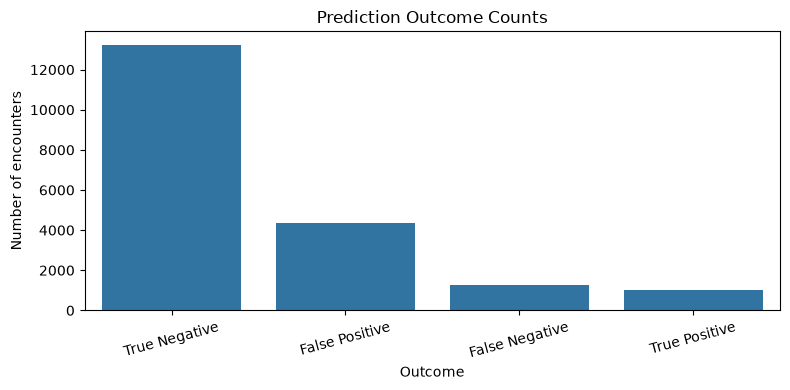

In [57]:
# Count each type of prediction outcome.

plt.figure(figsize=(8, 4))
sns.countplot(
    data=error_analysis,
    x="Outcome",
    order=["True Negative", "False Positive", "False Negative", "True Positive"]
)
plt.title("Prediction Outcome Counts")
plt.xlabel("Outcome")
plt.ylabel("Number of encounters")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [58]:
# Inspect false-negative cases — actual readmissions missed by the model.

false_negatives = error_analysis[
    (error_analysis["Actual"] == 1) &
    (error_analysis["Predicted"] == 0)
].sort_values("Risk Probability", ascending=False)

print("Number of false negatives:", len(false_negatives))
false_negatives.head(10)

Number of false negatives: 1256


,Actual,Predicted,Risk Probability,Outcome
12630,1,0,0.535954,False Negative
13288,1,0,0.535946,False Negative
63362,1,0,0.535745,False Negative
61371,1,0,0.535712,False Negative
58574,1,0,0.535684,False Negative
42356,1,0,0.535642,False Negative
42604,1,0,0.535433,False Negative
1417,1,0,0.535194,False Negative
7092,1,0,0.535185,False Negative
29568,1,0,0.534933,False Negative


In [59]:
# Inspect false-positive cases — patients flagged but not readmitted within 30 days.

false_positives = error_analysis[
    (error_analysis["Actual"] == 0) &
    (error_analysis["Predicted"] == 1)
].sort_values("Risk Probability", ascending=False)

print("Number of false positives:", len(false_positives))
false_positives.head(10)

Number of false positives: 4361


,Actual,Predicted,Risk Probability,Outcome
27412,0,1,0.927793,False Positive
30399,0,1,0.912426,False Positive
28462,0,1,0.907182,False Positive
77046,0,1,0.883561,False Positive
58070,0,1,0.882327,False Positive
91792,0,1,0.879405,False Positive
46440,0,1,0.875196,False Positive
68636,0,1,0.868884,False Positive
79226,0,1,0.861323,False Positive
52616,0,1,0.858242,False Positive


In [60]:
# Compare selected numerical features across the error groups.

numeric_error_features = [
    col for col in [
        "time_in_hospital", "num_lab_procedures", "num_procedures",
        "num_medications", "number_outpatient", "number_emergency",
        "number_inpatient", "number_diagnoses"
    ]
    if col in X_test.columns
]

error_profile = X_test[numeric_error_features].copy()
error_profile["Outcome"] = error_analysis["Outcome"]

error_profile.groupby("Outcome")[numeric_error_features].mean().round(2)

,time_in_hospital,num_lab_procedures,num_procedures,num_medications,number_outpatient,number_emergency,number_inpatient,number_diagnoses
Outcome,,,,,,,,
False Negative,4.54,44.00,1.36,15.92,0.35,0.11,0.19,7.47
False Positive,5.34,44.83,1.22,18.31,0.51,0.51,1.81,8.03
True Negative,4.05,42.11,1.40,15.17,0.30,0.08,0.16,7.15
True Positive,5.12,44.71,1.12,17.54,0.49,0.69,2.34,7.95


### 11.1 Error analysis interpretation

Use the tables and counts above to discuss:
- How many actual readmissions were missed (false negatives)?
- How many patients were incorrectly flagged (false positives)?
- Whether the model's errors are concentrated among patients with more previous hospital visits or longer stays.
- Whether a different threshold would be needed if hospital follow-up capacity is limited.

Do not assume a cause from correlation alone. The patterns are observations, not proof of causation.

# Part 12 — Patient-Level Prediction Report

The assignment asks for an illustrative patient-level report. We create it from the model's actual test predictions. The patient identifier is shown only as a pseudonymous record label for this notebook.

In [61]:
# Build the patient-level prediction report.

patient_report = pd.DataFrame({
    "Patient ID": [
        "Patient_" + str(value)
        for value in groups_test.loc[X_test.index].values
    ],
    "Actual Readmission": np.where(y_test_array == 1, "Yes", "No"),
    "Predicted Readmission": np.where(test_predictions == 1, "Yes", "No"),
    "Risk Probability": np.round(test_probabilities, 4)
}, index=X_test.index)

patient_report.head(10)

,Patient ID,Actual Readmission,Predicted Readmission,Risk Probability
0,Patient_8222157,No,No,0.1322
5,Patient_82637451,No,No,0.4419
8,Patient_48330783,No,Yes,0.5429
13,Patient_77586282,No,No,0.5326
22,Patient_63000108,No,No,0.4141
24,Patient_62718876,No,No,0.4075
25,Patient_21861756,No,No,0.1823
29,Patient_18196434,No,No,0.4126
30,Patient_56480238,No,No,0.3580
36,Patient_98427861,No,No,0.3965


In [62]:
# Assign simple risk tiers based on the predicted probability.

patient_report["Risk Tier"] = pd.cut(
    patient_report["Risk Probability"],
    bins=[-0.001, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"]
)

patient_report["Risk Tier"].value_counts()

Risk Tier
Medium    15005
Low        2536
High       2329
Name: count, dtype: int64

In [63]:
# Summarize the number of patients and observed readmissions in each risk tier.

tier_summary = patient_report.copy()
tier_summary["Actual Binary"] = y_test_array

tier_summary = tier_summary.groupby("Risk Tier", observed=False).agg(
    Patients=("Actual Binary", "size"),
    Actual_Readmissions=("Actual Binary", "sum"),
    Average_Risk=("Risk Probability", "mean")
)

tier_summary["Readmission Rate (%)"] = (
    tier_summary["Actual_Readmissions"] / tier_summary["Patients"] * 100
)

tier_summary.round(3)

,Patients,Actual_Readmissions,Average_Risk,Readmission Rate (%)
Risk Tier,,,,
Low,2536,115.0,0.240,4.535
Medium,15005,1606.0,0.456,10.703
High,2329,542.0,0.665,23.272


# Display the highest-risk patient encounters first.

patient_report.sort_values(
    "Risk Probability", ascending=False
).head(20)

In [65]:
# Save the prediction report as a CSV file.

report_file = "hospital_readmission_patient_predictions.csv"
patient_report.to_csv(report_file, index=False)

print("Prediction report saved as:", report_file)

Prediction report saved as: hospital_readmission_patient_predictions.csv


# Part 13 — Business Findings and Recommendations

### How a hospital could use the model output

1. **High-risk group:** Consider a nurse or care-coordinator call soon after discharge, medication reconciliation and an early follow-up appointment.
2. **Medium-risk group:** Consider reminder calls, follow-up scheduling and review of discharge instructions.
3. **Low-risk group:** Continue standard discharge guidance and routine follow-up.

These are illustrative operational suggestions. Any actual care decision must be made by qualified healthcare professionals and validated clinical processes.

In [66]:
# Generate a compact summary of the test-set results.

tn, fp, fn, tp = confusion_matrix(
    y_test_array, test_predictions, labels=[0, 1]
).ravel()

business_summary = pd.DataFrame({
    "Measure": [
        "Test encounters",
        "Actual 30-day readmissions",
        "Predicted 30-day readmissions",
        "True positives",
        "False positives",
        "False negatives",
        "True negatives",
        "Selected probability threshold",
        "Test ROC-AUC",
        "Test F1-score"
    ],
    "Value": [
        len(y_test_array),
        int(y_test_array.sum()),
        int(test_predictions.sum()),
        int(tp), int(fp), int(fn), int(tn),
        round(selected_threshold, 4),
        round(selected_metrics["ROC-AUC"], 4),
        round(selected_metrics["F1-score"], 4)
    ]
})

business_summary

,Measure,Value
0,Test encounters,19870.0000
1,Actual 30-day readmissions,2263.0000
2,Predicted 30-day readmissions,5368.0000
3,True positives,1007.0000
4,False positives,4361.0000
5,False negatives,1256.0000
6,True negatives,13246.0000
7,Selected probability threshold,0.5360
8,Test ROC-AUC,0.6512
9,Test F1-score,0.2639


In [67]:
# Print a short business findings statement using the model's measured results.

print("BUSINESS FINDINGS")
print("-----------------")
print(f"The model evaluated {len(y_test_array):,} held-out encounters.")
print(f"It identified {tp:,} true readmissions and missed {fn:,} actual readmissions.")
print(f"It generated {fp:,} false-positive alerts.")
print(f"The test ROC-AUC was {selected_metrics['ROC-AUC']:.3f}.")
print(f"The test recall was {selected_metrics['Recall']:.3f}.")
print()
print("Business implication:")
print("Hospitals can use risk scores as a way to prioritize human follow-up review,")
print("but the model should not replace clinical judgement.")

BUSINESS FINDINGS
-----------------
The model evaluated 19,870 held-out encounters.
It identified 1,007 true readmissions and missed 1,256 actual readmissions.
It generated 4,361 false-positive alerts.
The test ROC-AUC was 0.651.
The test recall was 0.445.

Business implication:
Hospitals can use risk scores as a way to prioritize human follow-up review,
but the model should not replace clinical judgement.


### 13.1 Limitations

- The data represents US hospital encounters from 1999–2008 and may not reflect current clinical practice.
- The target is based on recorded readmission categories and may not capture every readmission outside the observed data.
- Class imbalance can make accuracy look better than the model's ability to identify the minority class.
- The model is an educational prototype and has not been clinically validated.
- A real deployment would require privacy, fairness, prospective validation, workflow and regulatory reviews.

# Part 14 — Final Conclusion



In [68]:
# Optional: save the trained model for later use.

model.save("hospital_readmission_mlp.keras")
print("Trained model saved as hospital_readmission_mlp.keras")

Trained model saved as hospital_readmission_mlp.keras
